In [ ]:
# Import all neccessary libraries for data analysis and visualization.
# Pandas for data manipulation, numpy for numerical operations, Matplotlib and Seaborn for plotting
# datetime for handling date operations

In [5]:
# import required libraries
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, datetime, warnings

In [6]:
warnings.filterwarnings("ignore")

In [7]:
# Visualization styles
plt.style.use("seaborn-v0_8")
sns.set_palette("husl")
print("All required libraries imported successfully")

All required libraries imported successfully


In [8]:
# Load dataset
df = pd.read_csv("retail_sales.csv")
df.head(10)

,Date,Category,Sales,Quantity,Profit,Region
0,1/1/2023,Electronics,1149.014246,11.0,383.664245,North
1,1/1/2023,Clothing,958.520710,7.0,224.054049,East
2,1/1/2023,Home Goods,1473.763845,2.0,466.593090,South
3,1/1/2023,Sports,1230.230419,6.0,123.310460,West
4,1/1/2023,NaN?,828.585950,12.0,88.591355,East
5,1/2/2023,Electronics,722.775149,10.0,82.396149,West
6,1/2/2023,Clothing,788.996859,15.0,225.271072,West
7,1/2/2023,Home Goods,358.113803,3.0,128.198339,East
8,1/2/2023,Sports,819.923845,2.0,250.298077,East
9,1/2/2023,Books,1284.231946,7.0,363.436353,West


In [9]:
# Basic dataset information and structure
print("=== DATASET BASIC INFORMATION ===")
print(f"Dataset Dimensions: {df.shape[0]} rows x {df.shape[1]} columns")
print("\nColumn Names and Data Types: ")
print(df.dtypes)
print(df.isnull().sum())

=== DATASET BASIC INFORMATION ===
Dataset Dimensions: 1825 rows x 6 columns

Column Names and Data Types: 
Date            str
Category        str
Sales       float64
Quantity    float64
Profit      float64
Region          str
dtype: object
Date        0
Category    4
Sales       2
Quantity    5
Profit      0
Region      5
dtype: int64


In [10]:
# Cleaning---Filling in missing values, if any
print("\n Missing Values:")
print(df.isnull().sum())
print("\n Dataset Summary:")
df.info()
print("Fill in missing values.")
df["Category"] = df["Category"].fillna(df["Category"].mode()[0])
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].mean())
df.replace(["NaN", "nan", "NULL", "null", "", "NaN?", "Null", "Nan"], np.nan, inplace=True)
df.dropna(inplace=True)
print(df.isnull().sum())
df.head()


 Missing Values:
Date        0
Category    4
Sales       2
Quantity    5
Profit      0
Region      5
dtype: int64

 Dataset Summary:
<class 'pandas.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      1825 non-null   str    
 1   Category  1821 non-null   str    
 2   Sales     1823 non-null   float64
 3   Quantity  1820 non-null   float64
 4   Profit    1825 non-null   float64
 5   Region    1820 non-null   str    
dtypes: float64(3), str(3)
memory usage: 85.7 KB
Fill in missing values.
Date        0
Category    0
Sales       0
Quantity    0
Profit      0
Region      0
dtype: int64


,Date,Category,Sales,Quantity,Profit,Region
0,1/1/2023,Electronics,1149.014246,11.0,383.664245,North
1,1/1/2023,Clothing,958.520710,7.0,224.054049,East
2,1/1/2023,Home Goods,1473.763845,2.0,466.593090,South
3,1/1/2023,Sports,1230.230419,6.0,123.310460,West
5,1/2/2023,Electronics,722.775149,10.0,82.396149,West


In [11]:
# Data Type conversion and Cleaning
print("=== DATA CLEANING AND TYPE CONVERSION ===")
# convert Date to datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Extracting additional features from Date Column
df["Month"] = df["Date"].dt.month
df["Quarter"] = df["Date"].dt.quarter
df["DayOfWeek"] = df["Date"].dt.day_name()
df["MonthName"] = df["Date"].dt.month_name()
# Ensure numeric columns are properly formatted
numeric_columns = ["Sales", "Quantity", "Profit"]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors = "coerce")

print("Date types after conversion: ")
print(df.dtypes)
print(f"\n Date range: {df["Date"].min()} to {df["Date"].max()}")

=== DATA CLEANING AND TYPE CONVERSION ===
Date types after conversion: 
Date         datetime64[us]
Category                str
Sales               float64
Quantity            float64
Profit              float64
Region                  str
Month                 int32
Quarter               int32
DayOfWeek               str
MonthName               str
dtype: object

 Date range: 2023-01-01 00:00:00 to 2023-12-31 00:00:00


In [12]:
# Statistical Summary
print("=== STATISTICAL SUMMARY ===")
print("Descriptive statistics for Numerical columns:")
print(df[['Sales', 'Quantity', 'Profit']].describe())

=== STATISTICAL SUMMARY ===
Descriptive statistics for Numerical columns:
             Sales     Quantity       Profit
count  1814.000000  1814.000000  1814.000000
mean    980.685597    10.055246   248.131746
std     335.062884     5.508980   117.798840
min       0.000000     0.000000     0.000000
25%     783.973448     5.000000   156.719928
50%     997.160788    10.000000   228.855443
75%    1208.687315    15.000000   322.602484
max    1888.932537    19.000000   703.228418


In [13]:
# finding category-wise summary
print("\nCategory-wise Summary:")
category_summary = df.groupby('Category').agg({
    'Sales': ['count', 'sum', 'mean', 'std'],
    'Profit': ['sum', 'mean'],
    'Quantity': ['sum', 'mean']
}).round(2)
print(category_summary)


Category-wise Summary:
            Sales                                Profit         Quantity  \
            count        sum     mean     std       sum    mean      sum   
Category                                                                   
Books         364  370971.87  1019.15  336.39  92304.45  253.58  3737.00   
Clothing      369  355420.13   963.20  336.42  90889.44  246.31  3670.00   
Electronics   359  362373.70  1009.40  342.71  89635.86  249.68  3568.00   
Home Goods    362  344634.29   952.03  330.86  86993.11  240.31  3755.00   
Sports        360  345563.69   959.90  324.70  90288.13  250.80  3510.22   

                    
              mean  
Category            
Books        10.27  
Clothing      9.95  
Electronics   9.94  
Home Goods   10.37  
Sports        9.75  


In [14]:
# Trend analysics - Monthly sales
print("=== MONTHLY SALES TREND ANALYSIS ===")
# Monthly sales
monthly_sales = df.groupby(["Month", "MonthName"]).agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).reset_index()
monthly_sales = monthly_sales.sort_values('Month')
print("Monthly Sales Summary:")
print(monthly_sales)

=== MONTHLY SALES TREND ANALYSIS ===
Monthly Sales Summary:
    Month  MonthName          Sales        Profit     Quantity
0       1    January  138612.372413  35951.986096  1428.215385
1       2   February  132215.411776  34353.123612  1517.000000
2       3      March  145321.200626  38584.599285  1447.000000
3       4      April  138160.991209  37895.203187  1446.000000
4       5        May  150774.977103  40527.689566  1603.000000
5       6       June  152605.749860  39042.686605  1570.000000
6       7       July  162111.115687  40208.956109  1536.000000
7       8     August  148020.452251  34675.627875  1489.000000
8       9  September  153094.700793  37796.761379  1598.000000
9      10    October  151272.280840  36019.384158  1569.000000
10     11   November  146795.613628  36344.048332  1461.000000
11     12   December  159978.807192  38710.920857  1576.000000


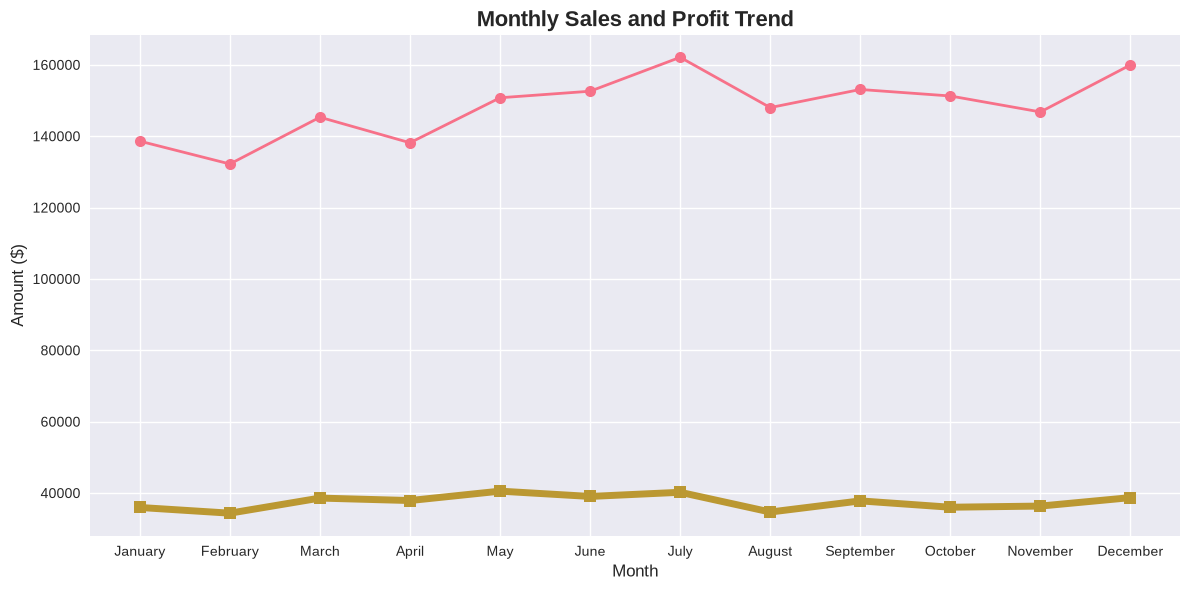

In [15]:
# Visualization 1: Monthly Sales Trend
plt.figure(figsize=(12,6))
plt.plot(monthly_sales["MonthName"], monthly_sales["Sales"], marker = "o", 
         linewidth=2, markersize=8, label="Total Sales")
plt.plot(monthly_sales["MonthName"], monthly_sales["Profit"], marker = 's', linewidth=5, markersize=8,
        label = "Total Profit")
plt.title("Monthly Sales and Profit Trend", fontsize=16, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Amount ($)", fontsize=12)
plt.tight_layout()
plt.show()

In [16]:
# category Performance Analysis
print("==== CATEGORY PERFORMANCE ANALYSIS ===")
category_performance = df.groupby("Category").agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).sort_values('Sales', ascending=False)
print("Category Performance (sorted by sales):")
print(category_performance)

==== CATEGORY PERFORMANCE ANALYSIS ===
Category Performance (sorted by sales):
                     Sales        Profit     Quantity
Category                                             
Books        370971.872558  92304.452141  3737.000000
Electronics  362373.695501  89635.859408  3568.000000
Clothing     355420.126737  90889.437106  3670.000000
Sports       345563.688429  90288.129853  3510.215385
Home Goods   344634.290152  86993.108551  3755.000000


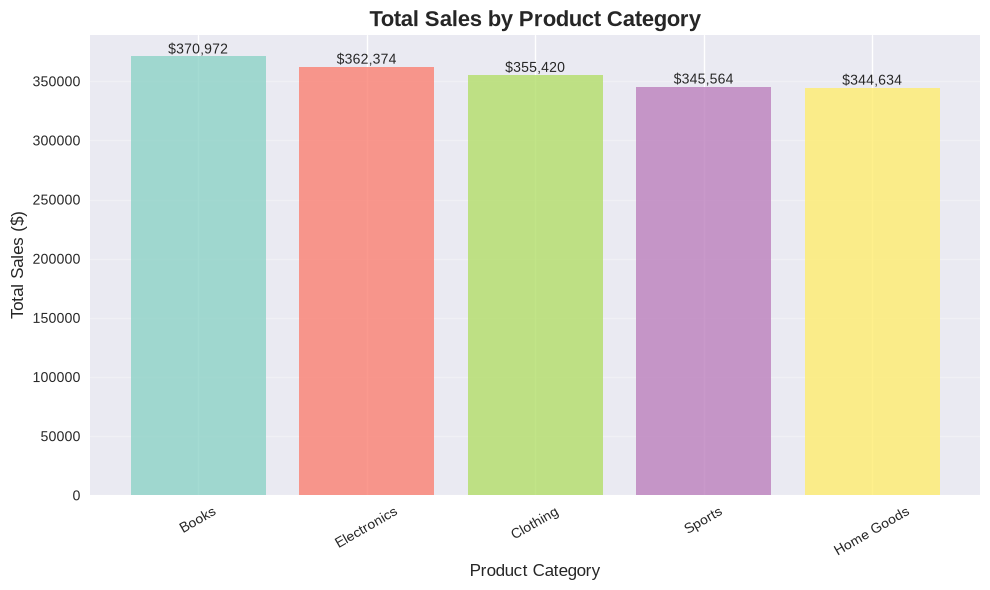

Date         0
Category     0
Sales        0
Quantity     0
Profit       0
Region       0
Month        0
Quarter      0
DayOfWeek    0
MonthName    0
dtype: int64
           Date     Category        Sales  Quantity      Profit Region  Month  \
0    2023-01-01  Electronics  1149.014246      11.0  383.664245  North      1   
1    2023-01-01     Clothing   958.520710       7.0  224.054049   East      1   
2    2023-01-01   Home Goods  1473.763845       2.0  466.593090  South      1   
3    2023-01-01       Sports  1230.230419       6.0  123.310460   West      1   
5    2023-01-02  Electronics   722.775149      10.0   82.396149   West      1   
...         ...          ...          ...       ...         ...    ...    ...   
1820 2023-12-31  Electronics  1132.749004      14.0  353.464221   West     12   
1821 2023-12-31     Clothing   679.261971       8.0  183.860200  North     12   
1822 2023-12-31   Home Goods  1193.733728      10.0  359.010938  South     12   
1823 2023-12-31       Sport

In [17]:
# Visualizing top categories by sales
from matplotlib import cm
plt.figure(figsize=(10,6))
colors = plt.colormaps["Set3"](np.linspace(0,1,len(category_performance)))
bars = plt.bar(category_performance.index, category_performance['Sales'], color= colors, alpha=0.8)

# Add value labels on bars
for bar in bars:
    heigth = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, heigth, f'${heigth:,.0f}', ha ='center', va= 'bottom')

plt.title('Total Sales by Product Category', fontsize=16, fontweight='bold')
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.xticks(rotation=30)
plt.grid(axis ='y', alpha=0.3)
plt.tight_layout()
plt.show()
df.head()
print(df.isna().sum())
print(df)


In [18]:
# Sales across different regions and create a Pie chart showing 
# distribution of sales by region
print("=== REGIONAL PERFORMANCE ANALYSIS ===")
regional_performance = df.groupby('Region').agg({
    'Sales': ['sum', 'mean', 'count'],
    'Profit': ['sum', 'mean']
}).round(2)

print("Regional Performance:")
print(regional_performance)

=== REGIONAL PERFORMANCE ANALYSIS ===
Regional Performance:
            Sales                   Profit        
              sum    mean count        sum    mean
Region                                            
East    392613.03  991.45   396   98626.81  249.06
North   448295.03  976.68   459  111564.65  243.06
South   468648.09  970.29   483  117783.54  243.86
West    469407.52  986.15   476  122135.99  256.59


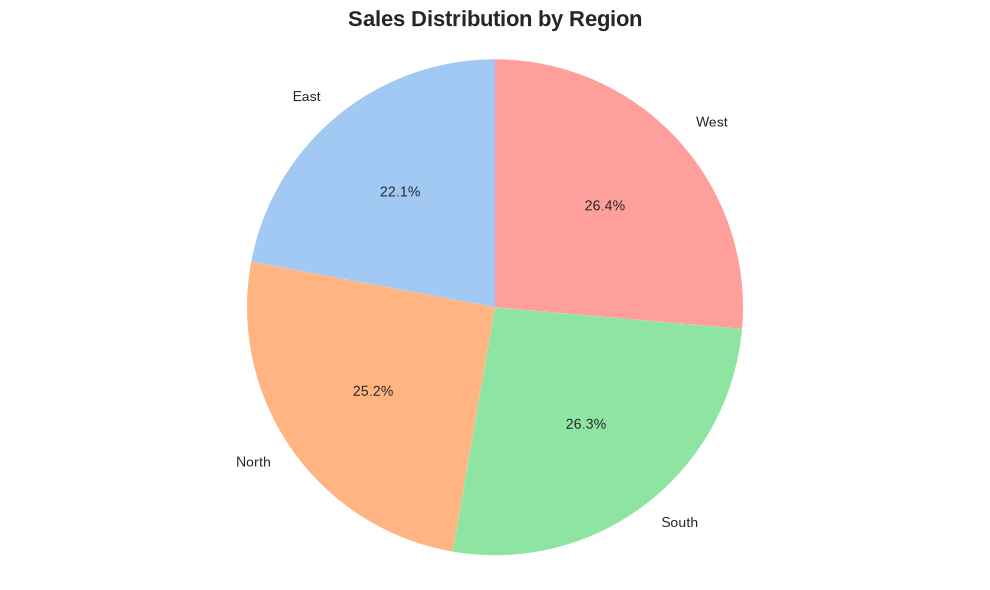

In [25]:
# Visualization - Regional Sales Distribution
plt.figure(figsize=(10,6))
regional_data = df.groupby('Region')['Sales'].sum()
plt.pie(regional_data, labels=regional_data.index, autopct='%1.1f%%', startangle=90, 
        colors=sns.color_palette('pastel'))
plt.title("Sales Distribution by Region", fontsize=16, fontweight= 'bold')
plt.axis('equal')
plt.axis('equal')
plt.tight_layout()
plt.show()

In [27]:
# Day of Week Analysis
print("=== DAY OF WEEK ANALYSIS ===")
# Days of the week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['DayOfWeek'] = pd.Categorical(df['DayOfWeek'], categories=day_order, ordered=True)
daily_performance = df.groupby('DayOfWeek').agg({
    'Sales': 'mean',
    'Profit': 'mean',
    'Quantity': 'mean'
}).round(2)
print("Average Performance by Day of Week")
print(daily_performance)

=== DAY OF WEEK ANALYSIS ===
Average Performance by Day of Week
             Sales  Profit  Quantity
DayOfWeek                           
Monday      980.74  252.24     10.23
Tuesday     982.88  241.21     10.31
Wednesday   964.43  237.69     10.21
Thursday    966.83  237.62      9.78
Friday     1011.72  259.84      9.97
Saturday    976.55  252.59      9.68
Sunday      981.69  255.57     10.21


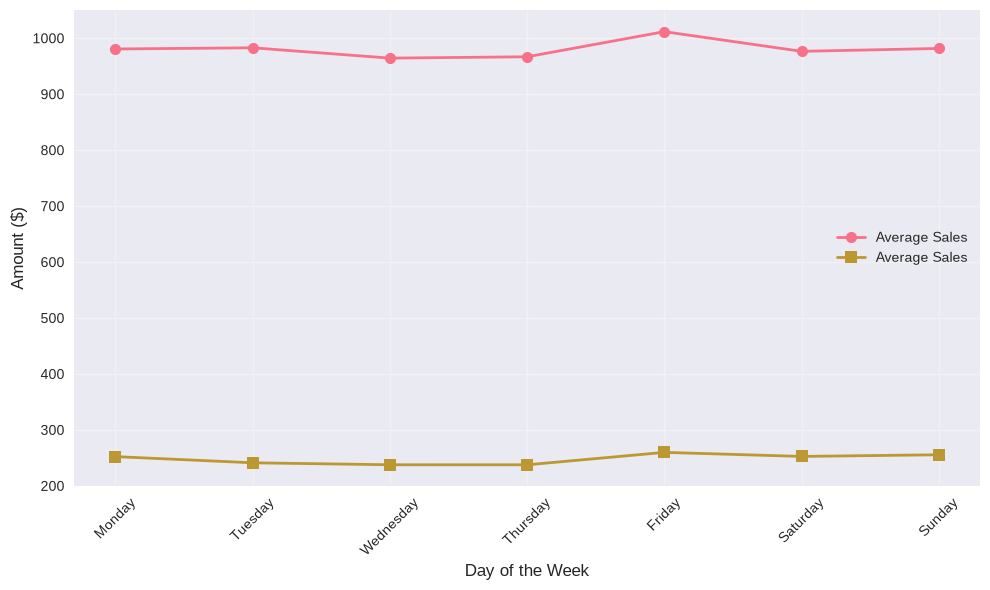

In [36]:
# Daily Sales pattern
plt.figure(figsize=(10,6))
plt.plot(daily_performance.index, daily_performance['Sales'],
         marker='o', linewidth=2, markersize=8, label='Average Sales')
plt.plot(daily_performance.index, daily_performance['Profit'], marker='s', linewidth=2, markersize=8,
         label='Average Sales')
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel('Amount ($)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

=== CORRELATION ANALYSIS ===
Correlation Matrix:
             Sales  Quantity    Profit     Month
Sales     1.000000  0.054341  0.531691  0.065227
Quantity  0.054341  1.000000  0.030310  0.002738
Profit    0.531691  0.030310  1.000000 -0.027400
Month     0.065227  0.002738 -0.027400  1.000000


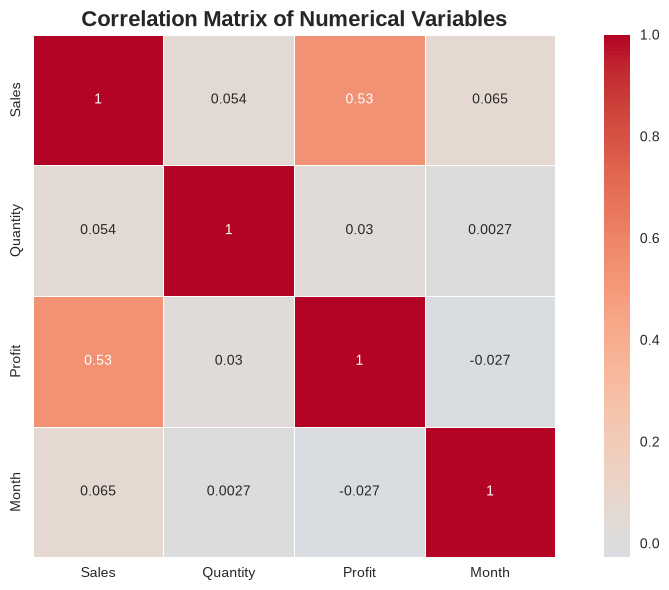

In [41]:
# Calculate correlation between numerical variables, and visualize the
# relationships between sales, quantity, profit, and time
print("=== CORRELATION ANALYSIS ===")
# select numerical columns for correlation
numerical_df = df[['Sales', 'Quantity', 'Profit', 'Month']]
correlation_matrix = numerical_df.corr()

print('Correlation Matrix:')
print(correlation_matrix)

#Heatmap visualization
plt.figure(figsize=(10,6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidth=0.5)
plt.title('Correlation Matrix of Numerical Variables', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [58]:
 # Key Insights and Business Recommendations
print("=== KEY INSIGHTS AND RECOMMENDATIONS ====")
print("\nKEY FINDINGS:")
print("1. Top Performing Category:", category_performance.index[0])
print("2. Best Performing Region:", regional_data.idxmax())
print("3. Highest Sales Month:", monthly_sales.loc[monthly_sales['Sales'].idxmax(), 'MonthName'])
print("4. Best Day of Week:", daily_performance['Sales'].idxmax())
print("5. Total Annual Sales: ${:,.2f}".format(df['Sales'].sum()))
print("6. Total Annual Profit: ${:,.2f}".format(df['Profit'].sum()))

=== KEY INSIGHTS AND RECOMMENDATIONS ====

KEY FINDINGS:
1. Top Performing Category: Books
2. Best Performing Region: West
3. Highest Sales Month: July
4. Best Day of Week: Friday
5. Total Annual Sales: $1,778,963.67
6. Total Annual Profit: $450,110.99


In [63]:
print("\n BUSINESS RECOMMENDATIONS:")
print("1. Invest more in marketing efforts for the", category_performance.index[0], "category")
print("2. Investigate performance in lower-performing regions")
print("3. Plan promotion around", daily_performance['Sales'].idxmax(), "to maximize sales")
print("4. Allocate inventory based on monthly trend patterns")
print("5. Monitor correlation between quantity and profit for pricing strategy")


 BUSINESS RECOMMENDATIONS:
1. Invest more in marketing efforts for the Books category
2. Investigate performance in lower-performing regions
3. Plan promotion around Friday to maximize sales
4. Allocate inventory based on monthly trend patterns
5. Monitor correlation between quantity and profit for pricing strategy


In [69]:
# Profitability Analysis
print("==== PROFITABILITY ANALYSIS === ")
profit_margin = (df['Profit'].sum() / df['Sales'].sum())*100
print(f"Overall Profit Margin: {profit_margin:.2f}%")
# Category Profit Margins
category_margins = (category_performance['Profit'] / category_performance['Sales']) * 100
print("\nProfit Margins by Category:")
for category, margin in category_margins.items():
    print(f" {category}: {margin:.2f}%")

==== PROFITABILITY ANALYSIS === 
Overall Profit Margin: 25.30%

Profit Margins by Category:
 Books: 24.88%
 Electronics: 24.74%
 Clothing: 25.57%
 Sports: 26.13%
 Home Goods: 25.24%
